In [121]:
### follow the file to analyze generic cubic and linear band spectrum 

In [122]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)
#from Minimal_Model_1D import *

#import Minimal_Model_1D as M

from Minimal_Model_1D import *


In [123]:
class modified_spin_orbit(oneD_Minimal_Model):

    def spin_orbit(self, i, j, s, so='cu', kx=0):

        """
        returns  <i,s|H_SO|j,sp>
        
        Args:
            i, j (int): refers to i and j th y subband sho wavefunction 
            s, sp (int){0 or 1}: refers to spin index up and down resp. for spin orbit, sp is opposite of s for spin orbit to be non zero
            so : spin orbit coupling, 'cu' if cubic rashba, 'li' if linear rashba
        
        """

        if so == 'cu':
            #print('cu')
            # cubic SOC #

            #k_minus_cube = self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) - 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) + 1j*self.Kycube_pr(i,j)*self.onedOP.iden()
            #k_plus_cube =  self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) + 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) - 1j*self.Kycube_pr(i,j)*self.onedOP.iden() 

            ### simplified cubic ###
            k_minus_cube = self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) - 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) + 1j*self.Kycube_pr(i,j)*self.onedOP.iden()
            k_plus_cube =  self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) + 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) - 1j*self.Kycube_pr(i,j)*self.onedOP.iden() 


            ### Note in later definitions, soc coupling is evoked only when s!=s' ###
            ### Hence not coding that statement here ###  

            if s==0:
                
                return -1j*self.alphat*k_minus_cube
            
            else:

                return 1j*self.alphat*k_plus_cube

        elif so == 'li':
            #print('li')
            # Linear SOC #

            if i==j:

                ### Note in later definitions, soc coupling is evoked only when s!=s' ###
                ### Hence not coding that statement here ###
                if s ==0 : 

                    return 1j*self.alphat*(self.onedOP.Kx(kx))
                
                else:

                    return -1j*self.alphat*(self.onedOP.Kx(kx))
                
            else :

                return self.alphat*(self.Ky_pr(i,j))*self.onedOP.iden()      
        
        else:

            return self.onedOP.zer()

In [5]:
N = 6
NSM = 2
NSC = 2
MY = 1
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 1000


#M_per = oneD_Minimal_Model(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)
M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 151)

KNUM = 3

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)


    

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150


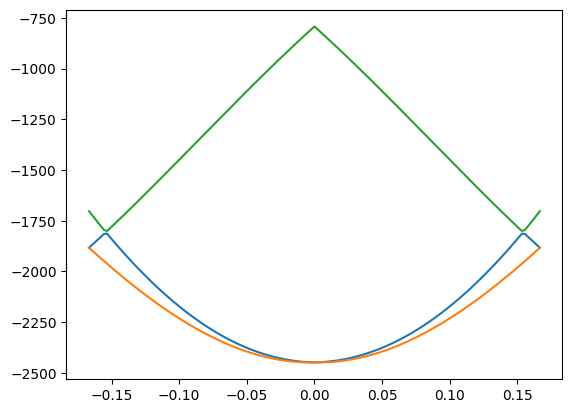

In [6]:
plt.plot(KX/np.pi, Ep[:,1])
plt.plot(KX/np.pi, Ep[:,2])
plt.plot(KX/np.pi, Ep[:,0])
#plt.ylim(ymax=-10500, ymin = -10620)
#plt.xlim(xmin= -0.05, xmax=0.05)

(-2500.0, -2000.0)

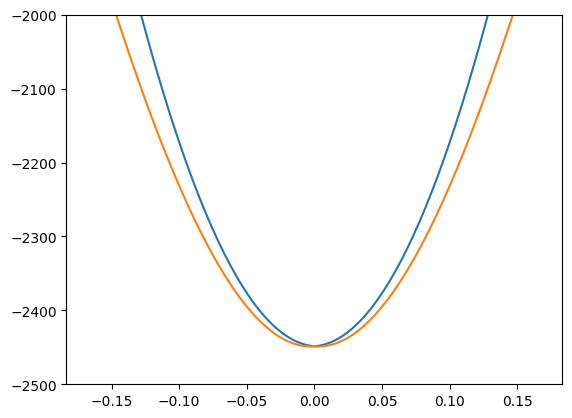

In [7]:
plt.plot(KX/np.pi, Ep[:,1])
plt.plot(KX/np.pi, Ep[:,2])
#plt.plot(KX/np.pi, Ep[:,0])
plt.ylim(ymax = -2000 , ymin = -2500)
#plt.xlim(xmin= -0.07, xmax=0.07)

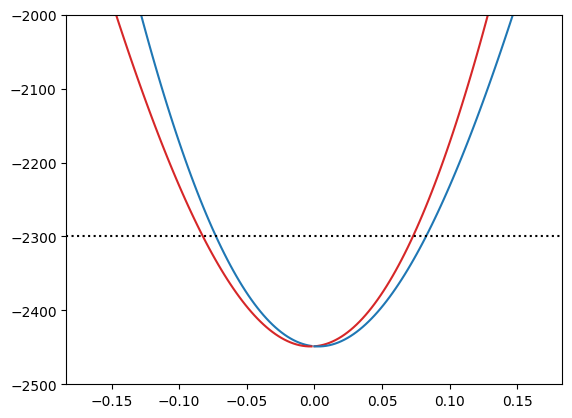

In [8]:
# Plot the first line before and after the midpoint
midpoint = len(KX) // 2

plt.plot(KX[:midpoint] / np.pi, Ep[:midpoint, 1], color='#1F77B4')  # First half with color 'blue'
plt.plot(KX[midpoint:] / np.pi, Ep[midpoint:, 1], color='#D62728')   # Second half with color 'red'

# Plot the second line before and after the midpoint
plt.plot(KX[:midpoint] / np.pi, Ep[:midpoint, 2], color='#D62728') # First half with color 'green'
plt.plot(KX[midpoint:] / np.pi, Ep[midpoint:, 2], color='#1F77B4')# Second half with color 'orange'

plt.axhline(y=-2300, color = 'black', linestyle='dotted')

plt.ylim(ymax = -2000 , ymin = -2500)

plt.show()

In [15]:
print(Ep[midpoint:, 1])

[-2448.61251242 -2448.16369287 -2447.46415461 -2446.51294822
 -2445.30916163 -2443.85192034 -2442.14038766 -2440.17376489
 -2437.95129157 -2435.47224567 -2432.73594376 -2429.74174127
 -2426.48903259 -2422.97725131 -2419.20587033 -2415.17440211
 -2410.88239871 -2406.32945204 -2401.51519394 -2396.43929633
 -2391.10147135 -2385.50147145 -2379.63908953 -2373.51415901
 -2367.12655396 -2360.47618917 -2353.56302025 -2346.38704367
 -2338.94829685 -2331.24685823 -2323.2828473  -2315.05642464
 -2306.56779198 -2297.81719223 -2288.80490945 -2279.53126894
 -2269.9966372  -2260.20142192 -2250.14607201 -2239.83107754
 -2229.25696977 -2218.42432105 -2207.33374486 -2195.98589568
 -2184.38146901 -2172.52120125 -2160.40586968 -2148.03629235
 -2135.41332799 -2122.53787596 -2109.41087611 -2096.03330869
 -2082.40619423 -2068.53059344 -2054.40760704 -2040.03837567
 -2025.42407969 -2010.5659391  -1995.46521332 -1980.12320106
 -1964.54124011 -1948.72070723 -1932.66301786 -1916.36962604
 -1899.84202411 -1883.08

In [30]:
### finding points closest to -2300 on red curve above +ve k 

number = -2300

print(np.shape(Ep[midpoint:, 1]))

temp_diff = np.abs(Ep[midpoint:, 1] - number)

# Get the indices of the 5 smallest differences
closest_indices = np.argpartition(temp_diff, 5)[:5]

closest_indices = np.sort(closest_indices)

print(closest_indices)

slope = np.empty(closest_indices.shape[0]-1)

Ep_after_mid = Ep[midpoint:, 1]

KX_after_mid = KX[midpoint:]

for i in range(closest_indices.shape[0]-1):

    di = closest_indices[i]
    df = closest_indices[i+1]

    slope[i] = (Ep_after_mid[di] - Ep_after_mid[di+1])/(KX_after_mid[di] - KX_after_mid[di+1])


print(slope)

(76,)
[31 32 33 34 35]
[1215.90706251 1253.43108575 1290.91441702 1328.35115451]


In [34]:
### finding points closest to -2300 on blue curve above +ve k 

number = -2300

print(np.shape(Ep[midpoint:, 2]))

temp_diff = np.abs(Ep[midpoint:, 2] - number)

# Get the indices of the 5 smallest differences
closest_indices = np.argpartition(temp_diff, 5)[:5]

closest_indices = np.sort(closest_indices)

print(closest_indices)

slope = np.empty(closest_indices.shape[0]-1)

Ep_after_mid2 = Ep[midpoint:, 2]

KX_after_mid = KX[midpoint:]

for i in range(closest_indices.shape[0]-1):

    di = closest_indices[i]
    df = closest_indices[i+1]

    slope[i] = (Ep_after_mid2[di] - Ep_after_mid2[di+1])/(KX_after_mid[di] - KX_after_mid[di+1])


print(slope)

(76,)
[35 36 37 38 39]
[1096.20801409 1123.71436983 1150.91477647 1177.80584218]


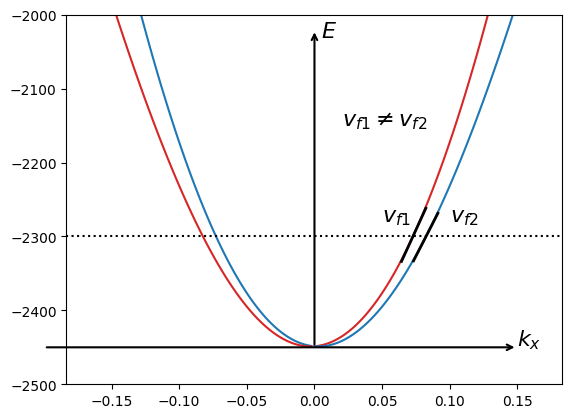

In [79]:
# Plot the first line before and after the midpoint
midpoint = len(KX) // 2


ind = 33

x0 = KX_after_mid[33]
y0 = Ep_after_mid[33]
sl0 = (1253+1290)/2

x = np.linspace(x0 + 0.009*np.pi, x0 - 0.009*np.pi, 21 )

ind2 = 37

x1 = KX_after_mid[37]
y1 = Ep_after_mid2[37]
sl1 = (1124+1151)/2

xp = np.linspace(x1 + 0.009*np.pi, x1 - 0.009*np.pi, 21 )


vf1_line = sl0*(x-x0) + y0
vf2_line = sl1*(xp-x1) + y1

plt.plot(KX[:midpoint] / np.pi, Ep[:midpoint, 1], color='#1F77B4')  # First half with color 'blue'
plt.plot(KX[midpoint:] / np.pi, Ep[midpoint:, 1], color='#D62728')   # Second half with color 'red'
plt.plot(x / np.pi, vf1_line, color='black', lw=2)


plt.text(0.05, -2280, r'$v_{f1}$', fontsize=16)    

# Plot the second line before and after the midpoint
plt.plot(KX[:midpoint] / np.pi, Ep[:midpoint, 2], color='#D62728') 
plt.plot(KX[midpoint:] / np.pi, Ep[midpoint:, 2], color='#1F77B4')
plt.plot(xp / np.pi, vf2_line, color='black', lw=2) 
plt.text(0.10, -2280, r'$v_{f2}$', fontsize=16)     

plt.text(0.02, -2150, r'$v_{f1} \neq v_{f2}$', fontsize=16)     

plt.axhline(y=-2300, color = 'black', linestyle='dotted')

# Plot a vertical line using axvline
x_pos = 0
#plt.axvline(x=x_pos, color='black', linestyle='solid')

# Add an arrow on the vertical line
plt.annotate('', xy=(x_pos, -2020), xytext=(x_pos, -2450),arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5))
plt.annotate('', xy=(0.15, -2450), xytext=(-0.20, -2450), arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5))
plt.text(0.005, -2030, r'$E$', fontsize=16)
plt.text(0.15, -2448, r'$k_{x}$', fontsize=16)

plt.ylim(ymax = -2000 , ymin = -2500)

plt.show()

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


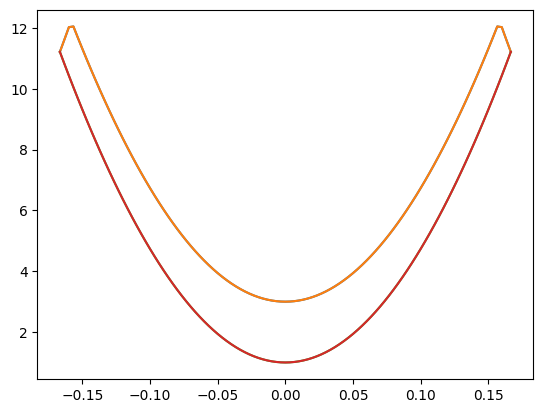

In [139]:
N = 6
NSM = 2
NSC = 2
MY = 2
AX = 1
OMEGA = 2 #IN meVs
ALPHAT = 0


M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 101)

KNUM = 4

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)

plt.plot(KX/np.pi, Ep)
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200


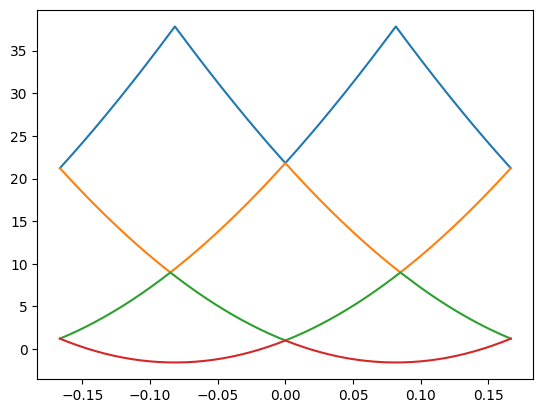

In [140]:
N = 6
NSM = 2
NSC = 2
MY = 1
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 20


M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 201)

KNUM = 4


Ep_one_band = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep_one_band[i, :] = E

    if i%5 == 0:

        print(i)


plt.plot(KX/np.pi, Ep_one_band)
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200


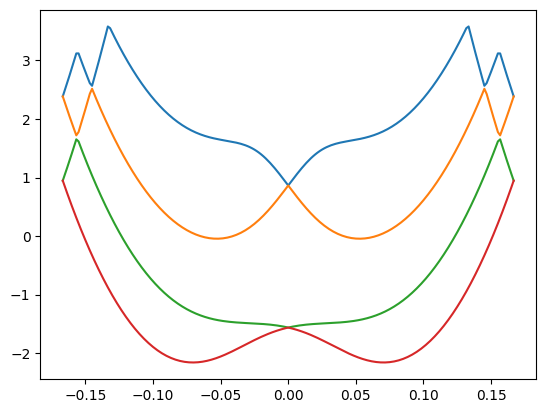

In [142]:
N = 6
NSM = 2
NSC = 2
MY = 5
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 20


M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 201)

KNUM = 4

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)


plt.plot(KX/np.pi, Ep)
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

(-0.05, 0.05)

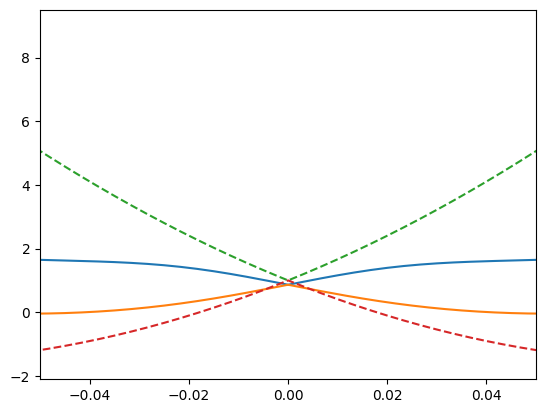

In [147]:

plt.plot(KX/np.pi, Ep[:, :2])
plt.plot(KX/np.pi, Ep_one_band[:, 2:], linestyle='dashed')
#plt.ylim(ymin=-10460, ymax = -10350)
plt.xlim(xmin= -0.05, xmax=0.05)

0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
150
155
160
165
170
175
180
185
190
195
200


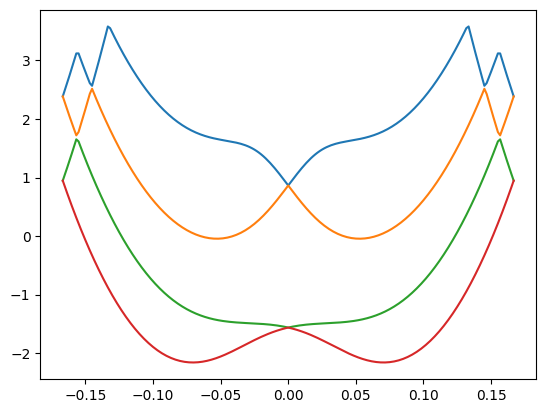

In [148]:
N = 6
NSM = 2
NSC = 2
MY = 5
AX = 1
OMEGA = 2 #IN MEv
ALPHAT = 20


M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 201)

KNUM = 4

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%5 == 0:

        print(i)


plt.plot(KX/np.pi, Ep)
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

(-0.135, 0.135)

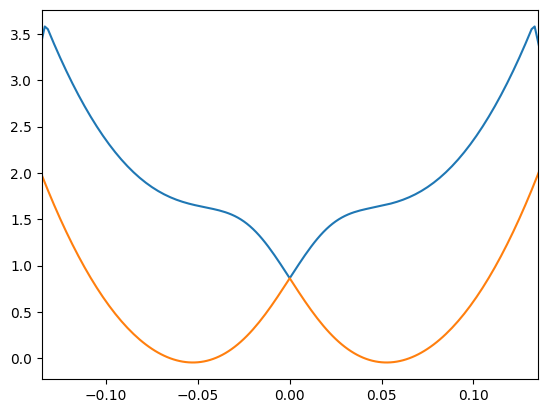

In [158]:
plt.plot(KX/np.pi, Ep[:,:2])
#plt.plot(KX/np.pi, Ep_one_band[:, 3], linestyle='dashed')
#plt.ylim(ymin=-10460, ymax = -10350)
plt.xlim(xmin= -0.135, xmax=0.135)

0
50
100
150
200


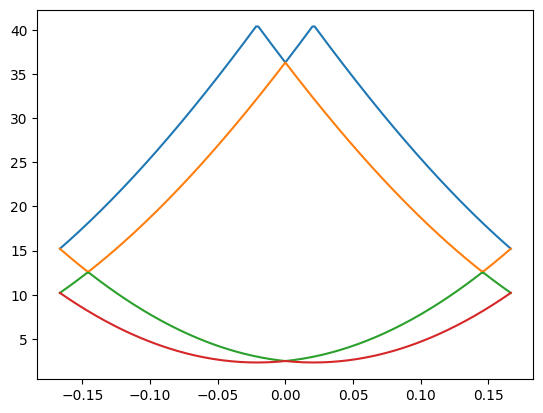

In [228]:
N = 6
NSM = 2
NSC = 2
MY = 1
AX = 1
OMEGA = 5 #IN MEv
ALPHAT = 5


M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 201)

KNUM = 4


Ep_one_band = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep_one_band[i, :] = E

    if i%50 == 0:

        print(i)


plt.plot(KX/np.pi, Ep_one_band)
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

0
50
100
150
200


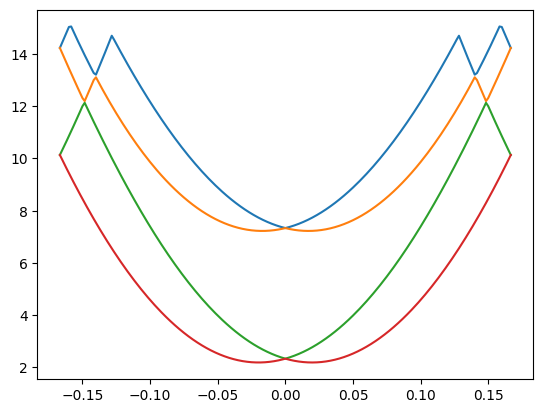

In [229]:
N = 6
NSM = 2
NSC = 2
MY = 5
AX = 1
OMEGA = 5 #IN MEv
ALPHAT = 5


M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 201)

KNUM = 4

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%50 == 0:

        print(i)


plt.plot(KX/np.pi, Ep)
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

In [259]:
### finding points closest to -2300 on red curve above +ve k 

number = 4.5

print(np.shape(Ep[midpoint:, 2]))

temp_diff = np.abs(Ep[midpoint:, 2] - number)

# Get the indices of the 5 smallest differences
closest_indices = np.argpartition(temp_diff, 5)[:5]

closest_indices = np.sort(closest_indices)

print(closest_indices)

slope = np.empty(closest_indices.shape[0]-1)

Ep_after_mid = Ep[midpoint:, 2]

KX_after_mid = KX[midpoint:]

for i in range(closest_indices.shape[0]-1):

    di = closest_indices[i]
    df = closest_indices[i+1]

    slope[i] = (Ep_after_mid[di] - Ep_after_mid[di+1])/(KX_after_mid[di] - KX_after_mid[di+1])


print(slope)

(101,)
[34 35 36 37 38]
[17.92851248 18.29803318 18.66638017 19.03351542]


In [260]:
### finding points closest to -2300 on blue curve above +ve k 

number = 4.5

print(np.shape(Ep[midpoint:, 3]))

temp_diff = np.abs(Ep[midpoint:, 3] - number)

# Get the indices of the 5 smallest differences
closest_indices = np.argpartition(temp_diff, 5)[:5]

closest_indices = np.sort(closest_indices)

print(closest_indices)

slope = np.empty(closest_indices.shape[0]-1)

Ep_after_mid2 = Ep[midpoint:, 3]

KX_after_mid = KX[midpoint:]

for i in range(closest_indices.shape[0]-1):

    di = closest_indices[i]
    df = closest_indices[i+1]

    slope[i] = (Ep_after_mid2[di] - Ep_after_mid2[di+1])/(KX_after_mid[di] - KX_after_mid[di+1])


print(slope)

(101,)
[57 58 59 60 61]
[17.96418491 18.3513528  18.73805199 19.12427108]


In [261]:
ind = 36

x0 = KX_after_mid[36]
y0 = Ep_after_mid[36]
sl0 = (18.3 + 18.7)/2

x = np.linspace(x0 + 0.009*np.pi, x0 - 0.009*np.pi, 21 )

ind2 = 59

x1 = KX_after_mid[59]
y1 = Ep_after_mid2[59]
sl1 = (18.35 + 18.74)/2

xp = np.linspace(x1 + 0.009*np.pi, x1 - 0.009*np.pi, 21 )


vf1_line = sl0*(x-x0) + y0
vf2_line = sl1*(xp-x1) + y1

(1.5472568959163793, 11.0)

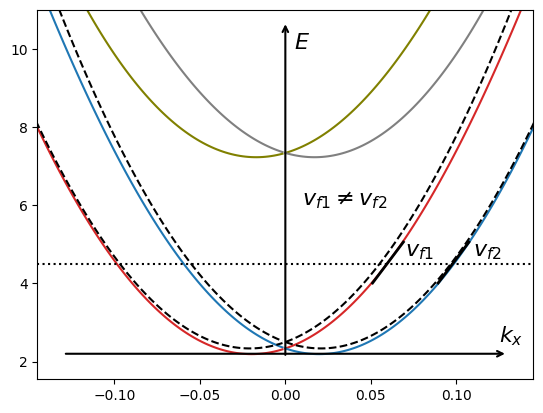

In [270]:
midpoint = len(KX) // 2


plt.plot(KX[:midpoint]/np.pi, Ep[:midpoint, 2], color='#1F77B4')
plt.plot(KX[midpoint:]/np.pi, Ep[midpoint:, 2], color='#D62728')
plt.plot(x / np.pi, vf1_line, color='black', lw=2)
plt.text(0.07, 4.7, r'$v_{f1}$', fontsize=16)    

plt.plot(KX[:midpoint]/np.pi, Ep[:midpoint, 3], color= '#D62728')
plt.plot(KX[midpoint:]/np.pi, Ep[midpoint:, 3], color= '#1F77B4')
plt.plot(xp / np.pi, vf1_line, color='black', lw=2)
plt.text(0.11, 4.7, r'$v_{f2}$', fontsize=16)    

plt.plot(KX[:midpoint]/np.pi, Ep_one_band[:midpoint,2], ls='dashed', color='black')
plt.plot(KX[midpoint:]/np.pi, Ep_one_band[midpoint:,2], ls='dashed', color='black')


plt.plot(KX[:midpoint]/np.pi, Ep_one_band[:midpoint,3], ls='dashed', color='black')
plt.plot(KX[midpoint:]/np.pi, Ep_one_band[midpoint:,3], ls='dashed', color='black')

plt.plot(KX[:midpoint]/np.pi, Ep[:midpoint, 0], color='#808080')
plt.plot(KX[midpoint:]/np.pi, Ep[midpoint:, 0], color='#808000')

plt.plot(KX[:midpoint]/np.pi, Ep[:midpoint, 1], color= '#808000')
plt.plot(KX[midpoint:]/np.pi, Ep[midpoint:, 1], color= '#808080')

plt.axhline(y=4.5, color = 'black', linestyle='dotted')

plt.text(0.01, 6, r'$v_{f1} \neq v_{f2}$', fontsize=16)  

# Add an arrow on the vertical line
plt.annotate('', xy=(0, 10.7), xytext=(0, 2.1),arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5))
plt.annotate('', xy=(0.13,2.2 ), xytext=(-0.13, 2.2), arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5))
plt.text(0.005, 10, r'$E$', fontsize=16)
plt.text(0.125, 2.5, r'$k_{x}$', fontsize=16)

plt.xlim(xmin=-0.145,xmax=0.145 )
plt.ylim(ymax = 11)